# Завдання 2. Зображення — це матриця чисел

**Виконала:** Шуховська В.

**Мета:** на маленькому зображенні дослідити, як значення елементів матриці задають яскравість пікселів, як індекси визначають їхнє розташування та чим розмір зображення відрізняється від розміру його відображення на екрані.

## 1. Початковий прогноз (до першого запуску)

Матриця G (4 рядки × 6 стовпців):

```
 0  40  80 120 160 200
20  60 100 140 180 220
30  70 110 150 190 230
50  90 130 170 210 250
```

Значення зростають зліва направо й зверху вниз, тому:

| | Комірка | Індекси | Значення |
|---|---|---|---|
| Найтемніший піксель | верхня ліва | `G[0, 0]` | 0 (чорний) |
| Найсвітліший піксель | нижня права | `G[3, 5]` | 250 (майже білий; 255 у матриці немає) |

## 2. Початковий код (без змін, `row=1, col=4, value=0`)

Початкова матриця:
 [[  0  40  80 120 160 200]
 [ 20  60 100 140 180 220]
 [ 30  70 110 150 190 230]
 [ 50  90 130 170 210 250]]
Змінена матриця:
 [[  0  40  80 120 160 200]
 [ 20  60 100 140   0 220]
 [ 30  70 110 150 190 230]
 [ 50  90 130 170 210 250]]
Форма: (4, 6)
Тип елементів: uint8
Кількість пікселів: 24
Обсяг даних пікселів: 24 байтів


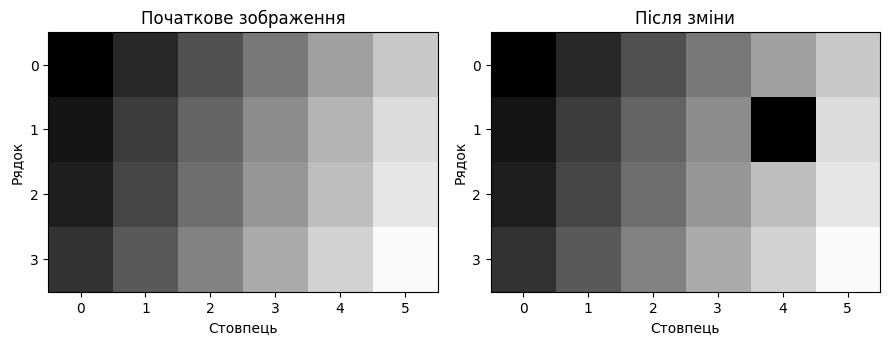

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Початкове зображення: кожне число задає яскравість одного пікселя.
G = np.array([
    [ 0, 40,  80, 120, 160, 200],
    [20, 60, 100, 140, 180, 220],
    [30, 70, 110, 150, 190, 230],
    [50, 90, 130, 170, 210, 250]
], dtype=np.uint8)

# Змінюйте ці параметри. Використовуйте цілі числа.
row = 1
col = 4
value = 0

if not (0 <= row < G.shape[0] and 0 <= col < G.shape[1]):
    raise ValueError("Індекс виходить за межі матриці")

if not 0 <= value <= 255:
    raise ValueError("Яскравість має бути від 0 до 255")

# Копія дозволяє порівнювати результат із незміненим оригіналом.
changed = G.copy()
changed[row, col] = value

print("Початкова матриця:\n", G)
print("Змінена матриця:\n", changed)
print("Форма:", G.shape)
print("Тип елементів:", G.dtype)
print("Кількість пікселів:", G.size)
print("Обсяг даних пікселів:", G.nbytes, "байтів")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, data, title in zip(
    axes,
    [G, changed],
    ["Початкове зображення", "Після зміни"]
):
    ax.imshow(
        data,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
        origin="upper"
    )
    ax.set_xticks(range(data.shape[1]))
    ax.set_yticks(range(data.shape[0]))
    ax.set_xlabel("Стовпець")
    ax.set_ylabel("Рядок")
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Порівняння з прогнозом:** найтемніший піксель (чорний) справді у верхньому лівому куті, найсвітліший — у нижньому правому куті. Прогноз справдився.

## 3. Допоміжна функція для експериментів

Щоб не копіювати код багато разів, той самий код обгорнуто у функцію `run(...)`. Під час кожного виклику `G` створюється заново, тому зміни **не накопичуються**, а кожен дослід порівнюється з одним і тим самим оригіналом. Параметри відображення (`vmin=0`, `vmax=255`, `interpolation="nearest"`, `origin="upper"`) не змінювались.

In [2]:
import os
os.makedirs("images", exist_ok=True)

def make_G():
    return np.array([
        [ 0, 40,  80, 120, 160, 200],
        [20, 60, 100, 140, 180, 220],
        [30, 70, 110, 150, 190, 230],
        [50, 90, 130, 170, 210, 250]
    ], dtype=np.uint8)

def run(row, col, value, figsize=(9, 4), G=None, save=None, quiet=False):
    G = make_G() if G is None else G
    if not (0 <= row < G.shape[0] and 0 <= col < G.shape[1]):
        raise ValueError("Індекс виходить за межі матриці")
    if not 0 <= value <= 255:
        raise ValueError("Яскравість має бути від 0 до 255")

    changed = G.copy()
    changed[row, col] = value

    old = int(G[row, col])
    trend = "темніший" if value < old else ("світліший" if value > old else "без змін")
    print(f"G[{row}, {col}]: {old} -> {value}  (піксель став {trend})")
    if not quiet:
        print("Форма:", G.shape, "| Кількість пікселів:", G.size,
              "| Обсяг даних:", G.nbytes, "байтів | figsize:", figsize)

    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, data, title in zip(axes, [G, changed], ["Початкове зображення", "Після зміни"]):
        ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                  interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        ax.set_title(title)
    plt.tight_layout()
    if save:
        fig.savefig(f"images/{save}.png", dpi=110)
    plt.show()
    return changed

## 4. Експерименти

### Експеримент 1. Зміна яскравості одного пікселя (`row=1, col=4`)
Початкове значення `G[1, 4] = 180`. Прогноз: значення 0, 64, 128 зроблять піксель **темнішим**, а 192 і 255 — **світлішим**.

G[1, 4]: 180 -> 0  (піксель став темніший)


Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


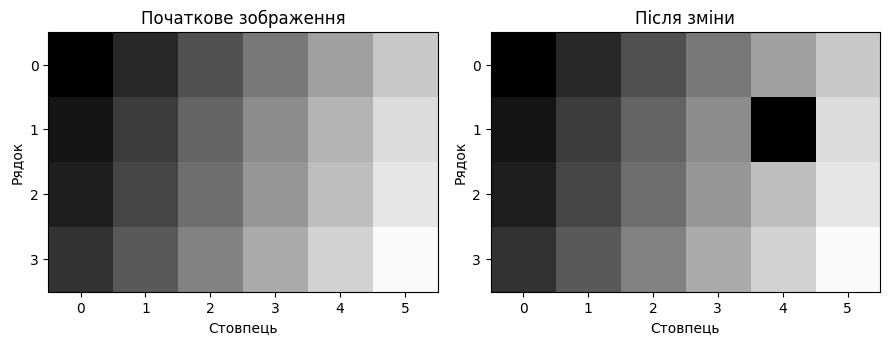

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140,   0, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [3]:
run(1, 4, 0, save="exp1_brightness_0")

G[1, 4]: 180 -> 64  (піксель став темніший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


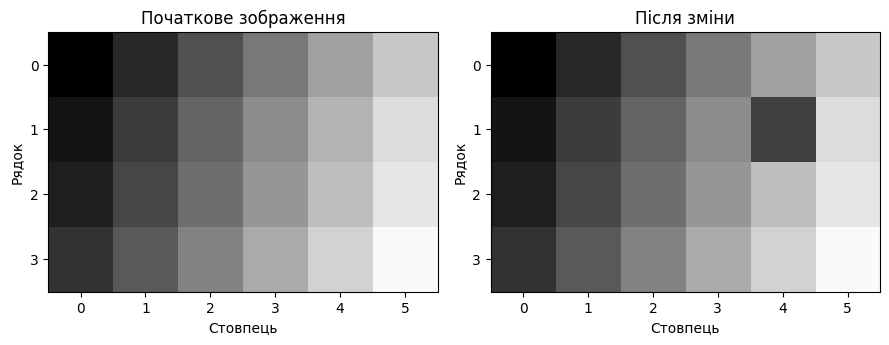

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140,  64, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [4]:
run(1, 4, 64, save="exp1_brightness_64")

G[1, 4]: 180 -> 128  (піксель став темніший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


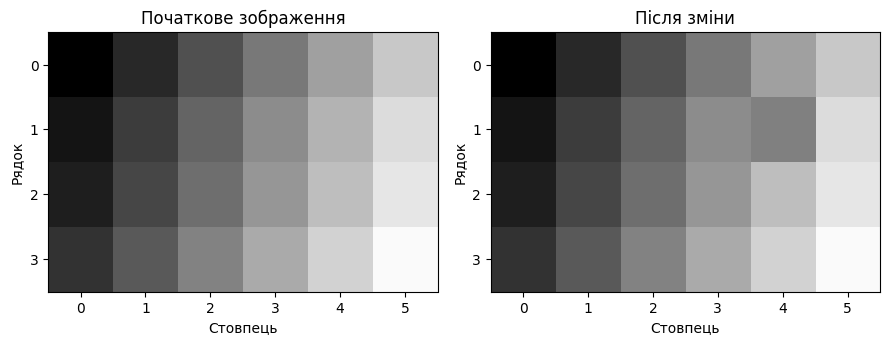

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 128, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [5]:
run(1, 4, 128, save="exp1_brightness_128")

G[1, 4]: 180 -> 192  (піксель став світліший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


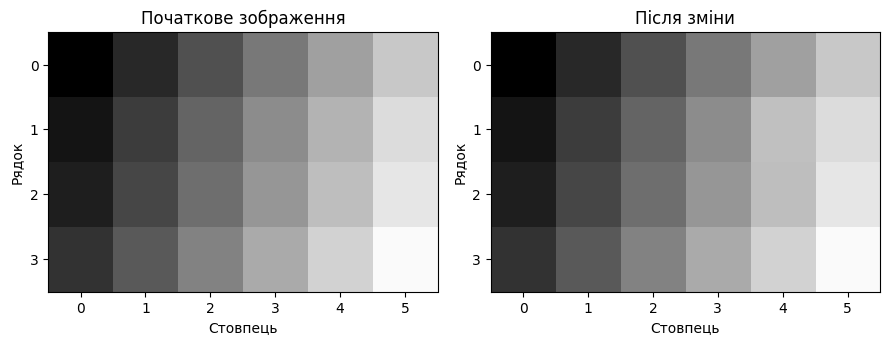

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 192, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [6]:
run(1, 4, 192, save="exp1_brightness_192")

G[1, 4]: 180 -> 255  (піксель став світліший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


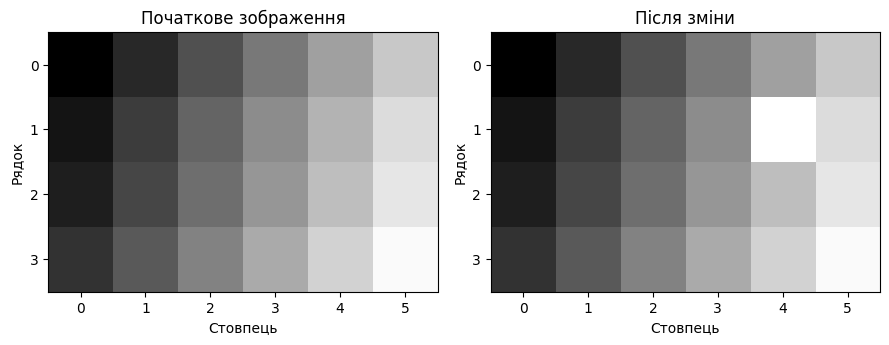

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 255, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [7]:
run(1, 4, 255, save="exp1_brightness_255")

### Експеримент 2. Перестановка індексів (`value=255`)
Початкові значення: `G[1, 3] = 140`, `G[3, 1] = 90`.  
Прогноз: перший запуск (`row=1, col=3`) зробить білим піксель у **2-му рядку, 4-му стовпці** (посередині зверху); другий запуск (`row=3, col=1`) — піксель у **4-му (нижньому) рядку, 2-му стовпці** (зліва знизу).

G[1, 3]: 140 -> 255  (піксель став світліший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


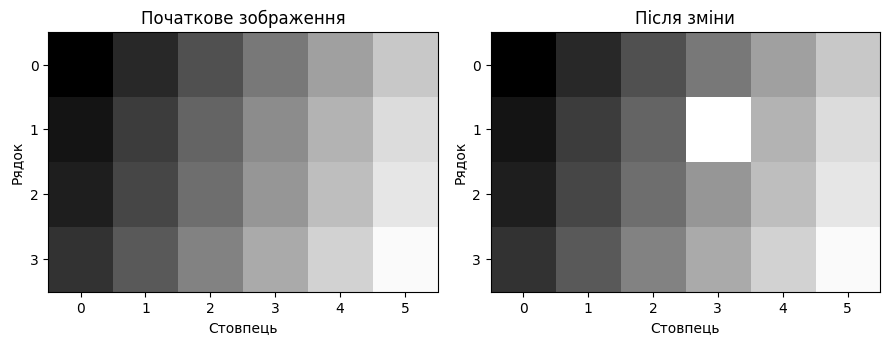

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 255, 180, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [8]:
run(1, 3, 255, save="exp2_first_run_row1_col3")

G[3, 1]: 90 -> 255  (піксель став світліший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


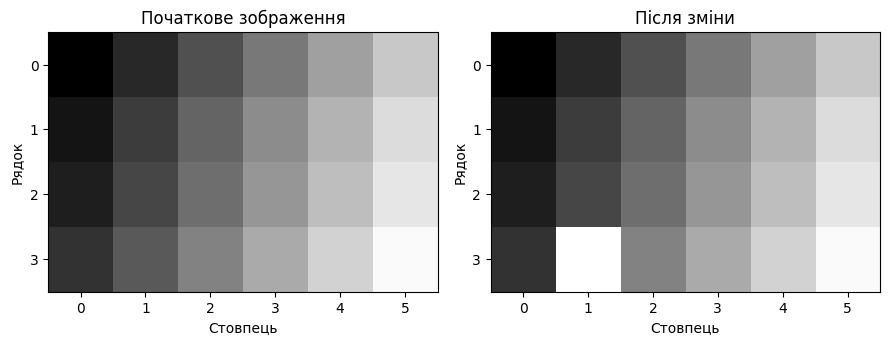

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 180, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50, 255, 130, 170, 210, 250]], dtype=uint8)

In [9]:
run(3, 1, 255, save="exp2_second_run_row3_col1")

### Експеримент 3. Кути зображення (`value=128`)
Розмір матриці 4×6, тому кути мають індекси: верхній лівий `(0, 0)`, верхній правий `(0, 5)`, нижній лівий `(3, 0)`, нижній правий `(3, 5)`.  
Прогноз: де початкове значення менше 128 — піксель посвітлішає (`(0,0)`: 0, `(3,0)`: 50); де більше — потемнішає (`(0,5)`: 200, `(3,5)`: 250).

G[0, 0]: 0 -> 128  (піксель став світліший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


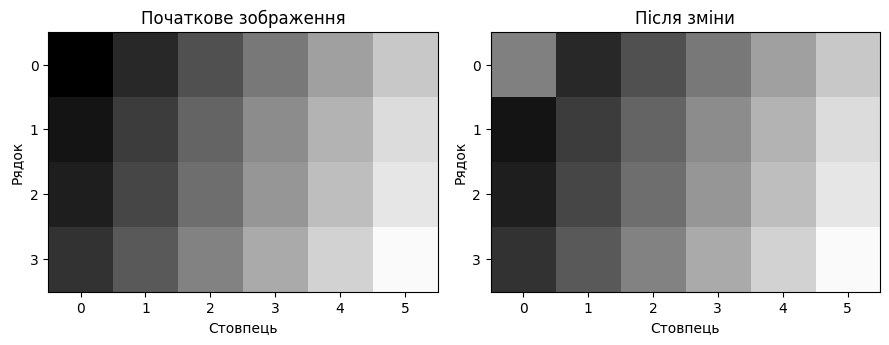

array([[128,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 180, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [10]:
run(0, 0, 128, save="exp3_top_left")

G[0, 5]: 200 -> 128  (піксель став темніший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


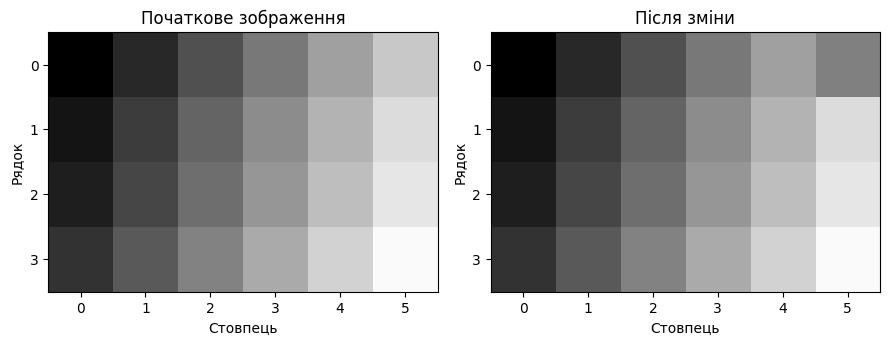

array([[  0,  40,  80, 120, 160, 128],
       [ 20,  60, 100, 140, 180, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [11]:
run(0, 5, 128, save="exp3_top_right")

G[3, 0]: 50 -> 128  (піксель став світліший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


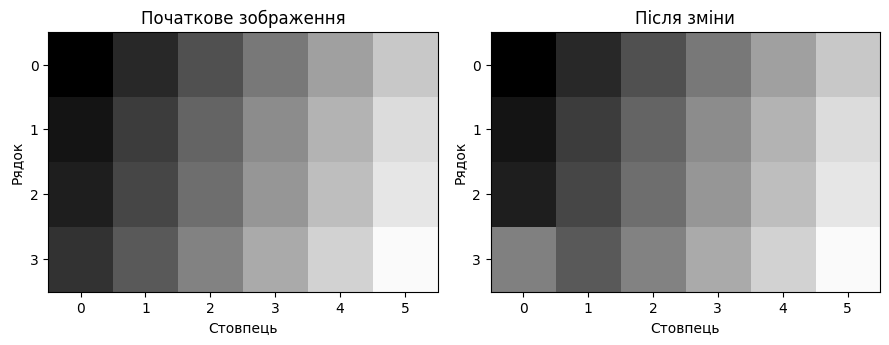

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 180, 220],
       [ 30,  70, 110, 150, 190, 230],
       [128,  90, 130, 170, 210, 250]], dtype=uint8)

In [12]:
run(3, 0, 128, save="exp3_bottom_left")

G[3, 5]: 250 -> 128  (піксель став темніший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


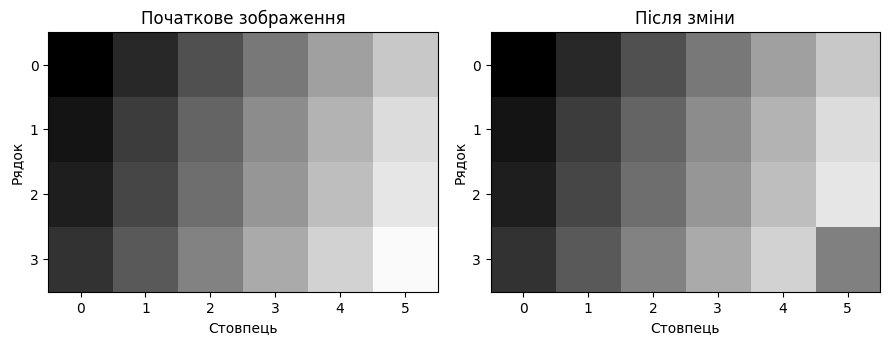

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140, 180, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 128]], dtype=uint8)

In [13]:
run(3, 5, 128, save="exp3_bottom_right")

### Експеримент 4. Масштаб відображення
Матриця не змінюється, змінюється лише `figsize`. Для наочності використано `row=1, col=4, value=0` (як у початковому коді).

G[1, 4]: 180 -> 0  (піксель став темніший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (9, 4)


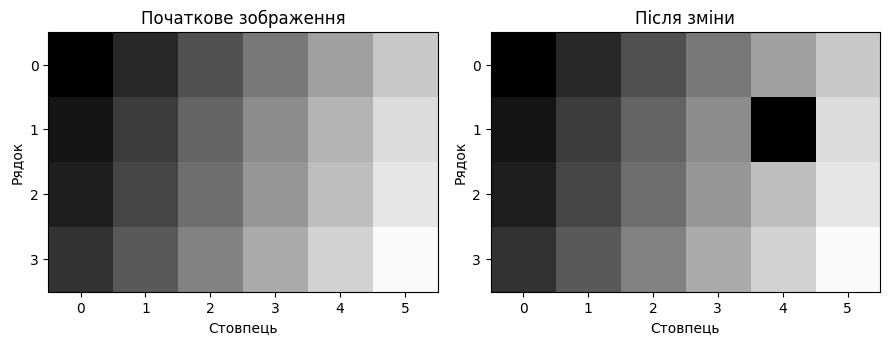

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140,   0, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [14]:
run(1, 4, 0, figsize=(9, 4), save="exp4_figsize_9x4")

G[1, 4]: 180 -> 0  (піксель став темніший)
Форма: (4, 6) | Кількість пікселів: 24 | Обсяг даних: 24 байтів | figsize: (12, 6)


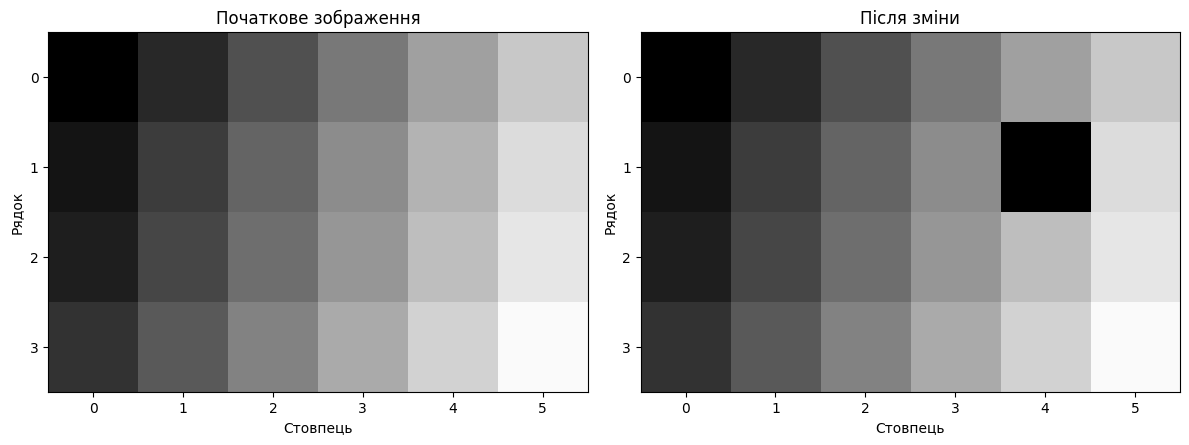

array([[  0,  40,  80, 120, 160, 200],
       [ 20,  60, 100, 140,   0, 220],
       [ 30,  70, 110, 150, 190, 230],
       [ 50,  90, 130, 170, 210, 250]], dtype=uint8)

In [15]:
run(1, 4, 0, figsize=(12, 6), save="exp4_figsize_12x6")

Після досліду `figsize` повернуто до `(9, 4)` (у функції `run` це значення за замовчуванням).

## 5. Таблиця результатів

| Дослід | Рядок `row` | Стовпець `col` | Початкове значення `G[row, col]` | Нове значення `value` | Прогноз | Що спостерігали |
|---|---|---|---|---|---|---|
| Яскравість: 0 | 1 | 4 | 180 | 0 | Піксель стане чорним, темнішим за початковий | Піксель чорний; темніший (180 → 0) |
| Яскравість: 64 | 1 | 4 | 180 | 64 | Темно-сірий, темніший | Темно-сірий; темніший (180 → 64) |
| Яскравість: 128 | 1 | 4 | 180 | 128 | Середньо-сірий, темніший | Середньо-сірий; темніший (180 → 128) |
| Яскравість: 192 | 1 | 4 | 180 | 192 | Світліший, але зміна мала | Трохи світліший (180 → 192); різницю лише 12 рівнів помітити важко |
| Яскравість: 255 | 1 | 4 | 180 | 255 | Білий, світліший | Піксель білий; світліший (180 → 255) |
| Перестановка індексів: перший запуск | 1 | 3 | 140 | 255 | Білий піксель у 2-му рядку, 4-му стовпці | Білий піксель у 2-му рядку, 4-му стовпці — прогноз справдився |
| Перестановка індексів: другий запуск | 3 | 1 | 90 | 255 | Білий піксель у 4-му рядку, 2-му стовпці | Білий піксель у нижньому рядку, 2-му стовпці — інше місце, ніж у першому запуску |
| Верхній лівий кут | 0 | 0 | 0 | 128 | Посвітлішає (чорний → сірий) | Піксель став сірим; світліший |
| Верхній правий кут | 0 | 5 | 200 | 128 | Потемнішає (світло-сірий → сірий) | Піксель став сірим; темніший |
| Нижній лівий кут | 3 | 0 | 50 | 128 | Посвітлішає | Піксель став сірим; світліший |
| Нижній правий кут | 3 | 5 | 250 | 128 | Потемнішає (майже білий → сірий) | Піксель став сірим; темніший |

Усі прогнози справдилися. Єдина «неочевидна» зміна — значення 192 (різниця з 180 дуже мала), але напрямок зміни (світліше) передбачено правильно.

### Таблиця масштабу відображення

| `figsize` | `G.shape` | `G.size` | `G.nbytes`, байтів | Що змінилося на екрані |
|---|---|---|---|---|
| (9, 4) | (4, 6) | 24 | 24 | Початкова (менша) область зображення |
| (12, 6) | (4, 6) | 24 | 24 | Область зображення більша, великі квадрати-пікселі збільшилися; дані матриці ті самі |

`shape` задає кількість рядків і стовпців, `size` — кількість елементів, `nbytes` — обсяг даних елементів масиву. `uint8` зберігає кожне значення в одному байті, тому 24 елементи займають 24 байти.

## 6. Власне зображення

Намальовано літеру **«Т»** на матриці 4×6 з трьома рівнями яскравості:

- **0** — фон (чорний);
- **255** — сама літера (білий);
- **128** — сірі «засічки» по краях верхньої перекладини.

Власна матриця:
 [[128 255 255 255 255 128]
 [  0   0 255 255   0   0]
 [  0   0 255 255   0   0]
 [  0   0 255 255   0   0]]
G[1, 2]: 255 -> 255  (піксель став без змін)


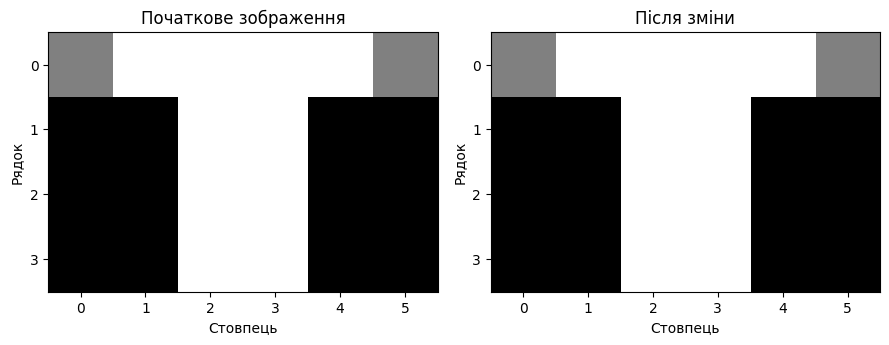

In [16]:
G_own = np.array([
    [128, 255, 255, 255, 255, 128],
    [  0,   0, 255, 255,   0,   0],
    [  0,   0, 255, 255,   0,   0],
    [  0,   0, 255, 255,   0,   0]
], dtype=np.uint8)

print("Власна матриця:\n", G_own)

row, col = 1, 2
value = int(G_own[row, col])   # щоб код не змінював додатковий піксель
_ = run(row, col, value, G=G_own, save="own_image_T", quiet=True)

**Відповідність комірок елементам малюнка:**

- `G_own[1, 2] = 255` — 2-й рядок, 3-й стовпець: білий піксель — верхня частина вертикальної ніжки літери «Т» (ліва половина ніжки). Яскравість 255 означає «частина літери».
- `G_own[0, 5] = 128` — 1-й рядок, 6-й стовпець: сірий піксель на правому краї верхньої перекладини («засічка»). Яскравість 128 — проміжний сірий, тому край виглядає м'якшим.
- Для порівняння: `G_own[1, 0] = 0` — чорний фон ліворуч від ніжки.

Оскільки `value = int(G_own[row, col])`, зображення «Після зміни» збігається з початковим — додаткових змін немає.

## 7. Відповіді на питання

**1. Що визначає значення елемента матриці, а що — його індекси?**  
Значення елемента (0…255) визначає яскравість пікселя: 0 — чорний, 255 — білий. Індекси `[row, col]` визначають розташування пікселя: рядок — відлік згори вниз, стовпець — зліва направо. У експерименті 1 піксель `G[1, 4]` залишався на тому самому місці, а зі зміною значення 180 → 0 → 64 → … → 255 змінювалась лише його яскравість.

**2. Чому `G[1, 3]` і `G[3, 1]` змінюють різні пікселі? Який індекс відповідає горизонтальному положенню?**  
У записі `G[row, col]` першим іде рядок (вертикальне положення), другим — стовпець (горизонтальне). `G[1, 3]` — це 2-й рядок, 4-й стовпець, а `G[3, 1]` — 4-й рядок, 2-й стовпець, тобто різні комірки (рядок і стовпець поміняні місцями). Горизонтальному положенню відповідає **другий індекс — `col`**.

**3. Чи змінилися кількість пікселів і обсяг їхніх даних після збільшення `figsize`?**  
Ні. В обох запусках `shape = (4, 6)`, `size = 24`, `nbytes = 24` (див. другу таблицю). Змінився лише розмір вікна/області відображення на екрані, а не дані зображення.

**4. Чому на екрані видно великі квадрати, хоча кожному відповідає один піксель матриці?**  
Матриця має лише 24 пікселі, а область осей на екрані містить тисячі екранних пікселів. Тому `imshow` розтягує кожен піксель матриці на великий блок. Через `interpolation="nearest"` значення не згладжуються, і кожен елемент матриці показується як рівномірний квадрат одного відтінку сірого.

## 8. Висновок

У роботі показано, що напівтонове зображення — це матриця чисел: значення елемента (0…255) задає яскравість пікселя, а пара індексів `[рядок, стовпець]` — його положення, причому рядки лічаться згори вниз, а стовпці зліва направо. Експерименти з `G[1, 3]` і `G[3, 1]` підтвердили, що порядок індексів має значення. Для масиву `uint8` розміром 4×6 `size = 24` і `nbytes = 24`, і ці значення не залежать від `figsize`, який змінює лише розмір відображення. Великі квадрати на екрані пояснюються тим, що кожен піксель матриці збільшено до блоку при `interpolation="nearest"`. Власну літеру «Т» створено зміною лише чисел у матриці з трьома рівнями яскравості.